# Object-Based Land-Cover Mapping of a Mining District (Obuasi, Ghana) with PyGeoVision OBIA

**From Sentinel-2 pixels to image objects, to a land-cover map, to a mine-footprint file the `mine_rehabilitation` pipeline can use**

---

### Honest scope statement

This notebook maps five land-cover classes -- **forest, farmland / regrowth, built-up, mine-disturbed ground, water** -- around Obuasi with *object-based image analysis*: the image is cut into objects first, each object gets spectral, shape, texture and context features, and objects (not pixels) are classified.

What it does **not** have, and what that means:

- **No field-collected training data.** The classifier learns from *weak labels*: ESA WorldCover (a model-made map at 10 m, with its own errors) plus OpenStreetMap mine outlines (partial, hand-drawn). Whatever those labels get wrong, the classifier partly learns. Scores computed against them are **agreement with the weak labels, not accuracy**, and the notebook says so wherever it reports one.
- **Accuracy needs an independent reference.** Section 9 uses a reference *points* file if you provide one (`REFERENCE_POINTS_PATH`). With none, the notebook stops short of quoting an accuracy.
- **Live data and a synthetic fallback.** Section 3 first tries a real Sentinel-2 download. If the network or credentials are missing, it falls back to a synthetic Obuasi-like scene (`obia.make_mine_scene`) so every cell still runs. The synthetic scene has the same problems as the real one -- cloud holes, imperfect weak labels, partial mine outlines -- *and* a known truth, which lets the notebook show how far a weak-label score can sit from the true accuracy. The synthetic numbers demonstrate the method; they say nothing about Obuasi.
- **Pure-Python region merging is slow on large areas.** The multiresolution segmentation handles about 0.4 million pixels in under a minute. The default live window is 5 km x 5 km (500 x 500 pixels). For a bigger area, tile it, or use `slic` / `felzenszwalb`, which are far faster.

The output that matters downstream is **`mine_site.geojson`**: the mine-disturbed objects dissolved into polygons, ready to be the `site` input of `pygeovision channel mine_rehabilitation`. Treat it as a first draft to be checked against imagery before anyone relies on it.

## 1. Setup

In [1]:
import os, sys, json, subprocess, warnings, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
warnings.filterwarnings("ignore")
import logging; logging.getLogger("pyogrio").setLevel(logging.WARNING)

import pygeovision as pgv
from pygeovision import obia
from pygeovision.obia.viz import plot_scale
from pygeovision.obia.io import rescale_bands, to_uint8

client = pgv.PyGeoVision()
print("PyGeoVision", getattr(pgv, "__version__", ""), "| OBIA segmentation methods:", ", ".join(obia.METHODS))

07:12:32 INFO [      engine] PyGeoFetch ready
PyGeoVision 2.1.9 | OBIA segmentation methods: multires, slic, felzenszwalb, quickshift, watershed, chessboard


## 2. Study area and parameters

Obuasi sits at about **6.20 N, 1.68 W** in Ashanti Region (Wikipedia gives these coordinates; the open pits and the AngloGold Ashanti operations are on its south and west sides). The default window below is a 5 km x 5 km square around that point. Everything you might want to change is in this one cell.

In [2]:
# ---- where, when --------------------------------------------------------------------------
AOI_BBOX = (-1.700, 6.180, -1.655, 6.225)   # (min_lon, min_lat, max_lon, max_lat), about 5 km x 5 km
DATE     = "2024-01"                        # Obuasi's dry season (Dec-Feb) has the fewest clouds
CLOUD_MAX = 30.0                            # scene-level cloud cover limit, percent

# ---- weak labels and (optional) independent reference ------------------------------------
# OSM mine polygons you downloaded earlier (any CRS). Skipped if the file is not there.
MINE_POLYGONS_PATH = "obuasi_site_osm.geojson"
DROP_NAME_REGEX    = "Plant|Processing"     # polygons whose `name` matches are not pits: left out
# Independent reference POINTS with a "class" column (forest, farmland, built_up, mine_disturbed, water),
# digitised by someone looking at high-resolution imagery, NOT taken from WorldCover/OSM. None = skip.
REFERENCE_POINTS_PATH = None

# ---- method -------------------------------------------------------------------------------
SCALE = 16            # multiresolution scale; Section 5 shows how to choose it
MIN_PURITY = 0.7      # an object takes a WorldCover class only if >= 70% of its pixels agree
OSM_COVERAGE = 0.6    # an OSM polygon labels an object as mine only if it covers >= 60% of it
MIN_MINE_HA = 0.5     # exported mine parts smaller than this are dropped
SEED = 0

MODE = os.environ.get("OBIA_NB_MODE", "auto")   # "auto" | "live" | "synthetic"
SHOW_DOWNLOAD_LOG = False                        # True: show the provider search / download messages
OUT = Path("obuasi_obia_outputs"); OUT.mkdir(exist_ok=True)

CLASSES = ["forest", "farmland", "built_up", "mine_disturbed", "water"]
COLORS  = {"forest": "#1b7837", "farmland": "#b8e186", "built_up": "#8c8c8c",
           "mine_disturbed": "#d6604d", "water": "#2166ac"}
CODE = {c: i + 1 for i, c in enumerate(CLASSES)}            # raster code per class, 0 = no data
# WorldCover code -> our class. Codes not listed (shrub 20, wetland 90, ...) are "something else".
# CAUTION: WorldCover's "bare / sparse vegetation" (60) is only *mostly* mining in this district -- it also holds
# fallow fields and quarries. That is why it is a weak label.
WC_MAP = {10: "forest", 30: "farmland", 40: "farmland", 50: "built_up", 60: "mine_disturbed", 80: "water"}

def paint(classes, labels):
    # class name per object -> uint8 raster in OUR class order (0 where the object has no class)
    lut = np.zeros(int(labels.max()) + 1, np.uint8)
    for oid, c in classes.items():
        lut[int(oid)] = CODE.get(c, 0)
    return lut[labels]

CMAP = ListedColormap(["#ffffff"] + [COLORS[c] for c in CLASSES])
LEGEND = [Patch(color=COLORS[c], label=c) for c in CLASSES]

## 3. Imagery

`obia.fetch_scene` downloads a cloud-masked Sentinel-2 L2A image (blue, green, red, NIR, SWIR1, SWIR2; reflectance 0-1) and returns it as a `RasterData`. Pixels hidden by cloud or shadow are **NaN in every band**; the OBIA functions treat them as "no data" (object label 0), and no object is ever built over them. If the download does not work, the cell prints why and builds the synthetic scene instead.

In [3]:
scene = None          # only set in synthetic mode: holds the truth and the stand-in weak-label data
rd = None
if MODE in ("auto", "live"):
    import contextlib, io, logging
    quiet = contextlib.nullcontext() if SHOW_DOWNLOAD_LOG else contextlib.ExitStack()
    try:
        with quiet as stack:
            if not SHOW_DOWNLOAD_LOG:
                stack.enter_context(contextlib.redirect_stdout(io.StringIO()))
                stack.enter_context(contextlib.redirect_stderr(io.StringIO()))
                logging.disable(logging.CRITICAL)
            try:
                rd = obia.fetch_scene(client, AOI_BBOX, DATE, OUT / "download", cloud_cover_max=CLOUD_MAX)
            finally:
                logging.disable(logging.NOTSET)
        print(f"LIVE Sentinel-2 scene: {rd.image.shape[1]} x {rd.image.shape[2]} px, CRS {rd.crs}")
    except Exception as exc:
        if MODE == "live":
            raise
        print(f"Live download not possible here ({type(exc).__name__}: {str(exc)[:200]})")
if rd is None:
    scene = obia.make_mine_scene(size=240, seed=SEED)
    rd = scene.raster
    print(f"SYNTHETIC Obuasi-like scene: {rd.image.shape[1]} x {rd.image.shape[2]} px at 10 m, CRS {rd.crs}")
    print("Every number below comes from invented data. It shows the method, not Obuasi.")
LIVE = scene is None

valid = obia.valid_mask(rd)
PIX_HA = rd.pixel_area / 1e4
print(f"bands: {rd.band_names}")
print(f"no-data (cloud/shadow) pixels: {(~valid).sum():,} = {100 * (~valid).mean():.1f}% of the scene = {(~valid).sum() * PIX_HA:,.0f} ha")

KeyboardInterrupt: 

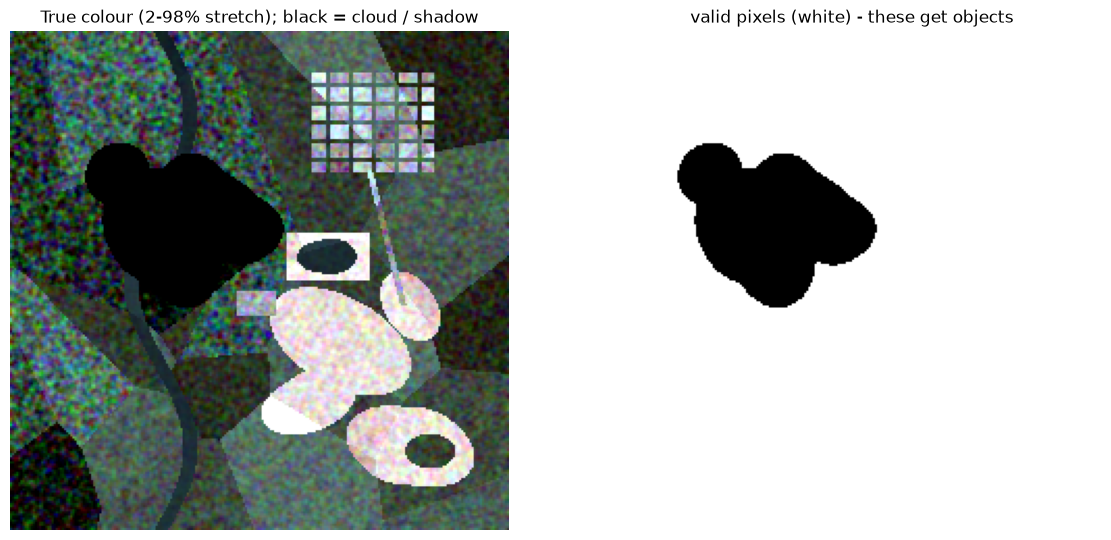

In [4]:
rgb = np.moveaxis(to_uint8(rescale_bands(rd.image[[2, 1, 0]])), 0, -1)
fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))
ax[0].imshow(rgb); ax[0].set_title("True colour (2-98% stretch); black = cloud / shadow"); ax[0].axis("off")
ax[1].imshow(valid, cmap="gray"); ax[1].set_title("valid pixels (white) - these get objects"); ax[1].axis("off")
plt.tight_layout(); plt.show()

## 4. Mining-relevant spectral indices

OBIA's `extract_features` gives every object mean / std / min / max of each band **and of any extra layer you pass in**. So the indices are computed once, as full-image layers, and every object inherits their statistics. NaN pixels stay NaN and are left out of every object statistic.

| Index | Formula | Why it helps here |
|---|---|---|
| NDVI | (NIR - Red) / (NIR + Red) | forest and crops vs. everything bare |
| MNDWI | (Green - SWIR1) / (Green + SWIR1) | water, including tailings ponds and pit lakes |
| BSI | ((SWIR1 + Red) - (NIR + Blue)) / ((SWIR1 + Red) + (NIR + Blue)) | exposed soil, spoil and tailings |
| NDBI | (SWIR1 - NIR) / (SWIR1 + NIR) | built-up and bare surfaces |

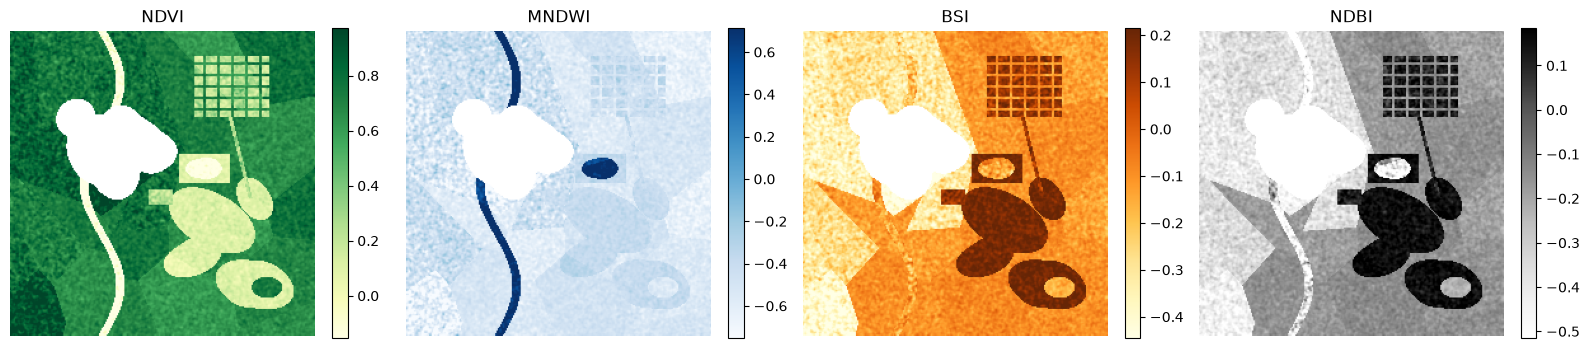

In [5]:
b = {n: rd.image[i].astype(np.float64) for i, n in enumerate(rd.band_names)}
eps = 1e-9
layers = {
    "ndvi":  (b["nir"] - b["red"]) / (b["nir"] + b["red"] + eps),
    "mndwi": (b["green"] - b["swir1"]) / (b["green"] + b["swir1"] + eps),
    "bsi":   ((b["swir1"] + b["red"]) - (b["nir"] + b["blue"])) / ((b["swir1"] + b["red"]) + (b["nir"] + b["blue"]) + eps),
    "ndbi":  (b["swir1"] - b["nir"]) / (b["swir1"] + b["nir"] + eps),
}
fig, ax = plt.subplots(1, 4, figsize=(16, 4.3))
for a, (name, arr), cm in zip(ax, layers.items(), ["YlGn", "Blues", "YlOrBr", "Greys"]):
    im = a.imshow(arr, cmap=cm, vmin=np.nanpercentile(arr, 2), vmax=np.nanpercentile(arr, 98)); a.set_title(name.upper()); a.axis("off")
    plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()

## 5. Segmentation: cutting the image into objects

Multiresolution segmentation merges neighbouring pixels while the *increase in heterogeneity* stays below `scale`². A small scale gives many small objects, a large one few large ones. Too small (**over-segmentation**) and objects are fragments that carry little shape information; too large (**under-segmentation**) and one object swallows two land covers, an error no classifier can repair. So the scale is the most consequential choice in OBIA.

Two ways to choose it:

1. **Without reference objects** (the only option on real data): the rate of change of local variance (ROC-LV) has peaks at scales where the objects change character. It is a *heuristic* -- it nominates candidates, you check them by eye.
2. **With reference objects** (only the synthetic scene has them): measure over- and under-segmentation directly and pick the scale with the smallest combined distance `D`.

,n_objects,lv,roc_lv,candidate
scale,,,,
5.0,2557,11.10,NaN,False
8.0,1304,13.22,19.11,False
12.0,461,15.91,20.38,True
16.0,251,16.96,6.57,False
20.0,181,16.58,-2.24,False
30.0,110,16.97,2.32,True
40.0,89,16.11,-5.03,False


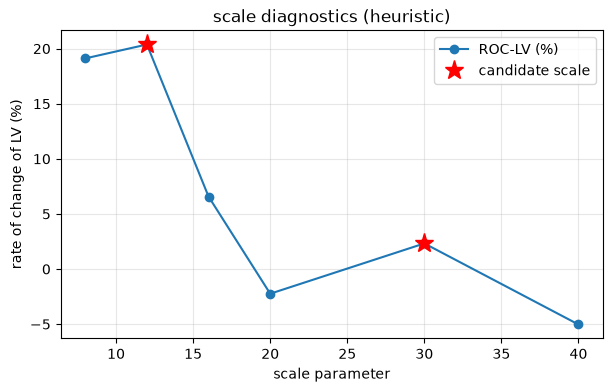

ROC-LV candidate scales (heuristic): [12.0, 30.0]


In [6]:
SCALES = [5, 8, 12, 16, 20, 30, 40]
diag = obia.scale_diagnostics(rd, SCALES)
display(diag.round(2))
plot_scale(diag); plt.show()
print("ROC-LV candidate scales (heuristic):", diag.index[diag["candidate"]].tolist())

,n_objects,mean_over_seg,mean_under_seg,mean_D,mean_QR
scale,,,,,
5.0,2557,0.482,0.190,0.460,0.348
8.0,1304,0.395,0.224,0.418,0.406
12.0,461,0.224,0.259,0.323,0.541
16.0,251,0.133,0.314,0.298,0.575
20.0,181,0.097,0.376,0.312,0.558
30.0,110,0.067,0.487,0.370,0.476
40.0,89,0.054,0.545,0.402,0.434


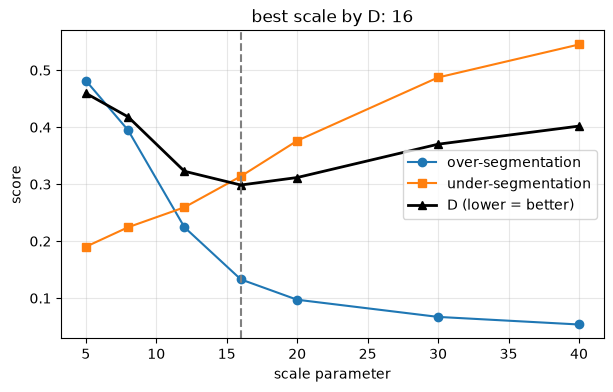

best scale against the TRUE objects: 16   (SCALE in use: 16)


In [7]:
if not LIVE:
    # DEMO ONLY: the synthetic scene has true object outlines, a luxury real data does not have
    q = obia.scale_vs_reference(rd, SCALES, scene.ref_labels)
    display(q.round(3))
    plot_scale(q); plt.show()
    print(f"best scale against the TRUE objects: {q['mean_D'].idxmin():g}   (SCALE in use: {SCALE})")
else:
    print("Live scene: no reference objects, so there is no D. Pick SCALE from the candidates above, then look at the overlay below.")

251 objects at scale 16; label 0 (no data) covers 4,759 px


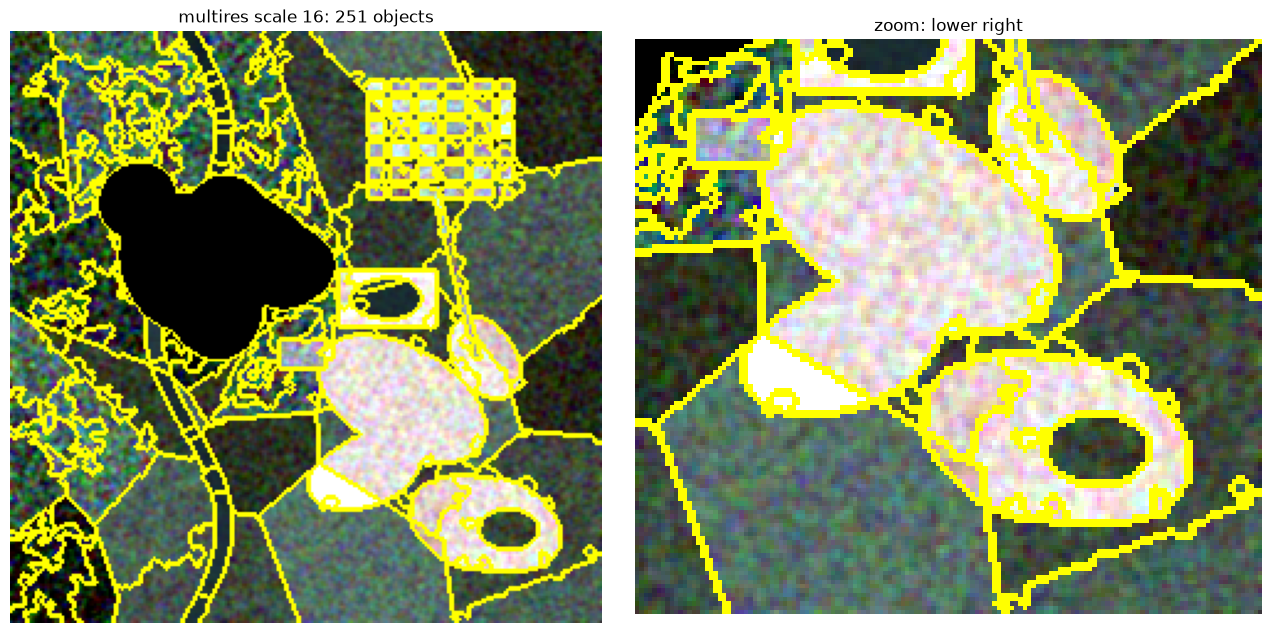

In [8]:
seg = obia.segment(rd, "multires", scale=SCALE)
lab = seg.labels
print(f"{seg.n_objects} objects at scale {SCALE}; label 0 (no data) covers {(lab == 0).sum():,} px")
assert ((lab == 0) == ~valid).all(), "label 0 must be exactly the cloud/shadow pixels"

H, W = lab.shape
fig, ax = plt.subplots(1, 2, figsize=(13, 6.3))
ax[0].imshow(seg.overlay((2, 1, 0))); ax[0].set_title(f"multires scale {SCALE}: {seg.n_objects} objects"); ax[0].axis("off")
r0, c0 = int(H * .45), int(W * .40)
ax[1].imshow(seg.overlay((2, 1, 0))[r0:, c0:]); ax[1].set_title("zoom: lower right"); ax[1].axis("off")
plt.tight_layout(); plt.show()

## 6. Object features

For each object: mean / std / min / max of every band and index, **shape** (area, compactness, elongation, solidity), **texture** (GLCM contrast, homogeneity, entropy ... on NIR) and **context** (number of neighbours, difference to neighbours). The shape and texture columns are what separate classes that look alike spectrally, e.g. compact built-up blocks from irregular spoil heaps.

In [9]:
F = obia.extract_features(lab, rd, extra_layers=layers, texture_layers=["nir"], transform=rd.transform)
print(f"{F.shape[0]} objects x {F.shape[1]} features")
print("feature families:",
      {"spectral": sum(c.startswith(("mean_", "std_", "min_", "max_")) for c in F.columns),
       "shape": sum(c in ("area_px", "area_m2", "perimeter_px", "compactness", "shape_index", "elongation", "solidity", "extent") for c in F.columns),
       "texture": sum(c.startswith("glcm_") for c in F.columns),
       "context": sum(c.startswith(("n_neighbors", "rel_border", "diff_to")) for c in F.columns)})
assert F.index.min() >= 1 and len(F) == lab.max()
area_ha = F["area_m2"] / 1e4
F[["area_m2", "mean_ndvi", "mean_bsi", "mean_mndwi", "compactness", "glcm_contrast_nir", "n_neighbors"]].describe().round(3)

251 objects x 72 features
feature families: {'spectral': 40, 'shape': 8, 'texture': 6, 'context': 12}


,area_m2,mean_ndvi,mean_bsi,mean_mndwi,compactness,glcm_contrast_nir,n_neighbors
count,251.000,251.000,251.000,251.000,251.000,204.000,251.000
mean,21052.191,0.554,-0.153,-0.389,0.423,1.063,4.478
std,47603.025,0.334,0.204,0.348,0.213,2.236,3.655
min,100.000,-0.240,-0.597,-0.955,0.037,0.000,1.000
25%,1800.000,0.236,-0.310,-0.537,0.239,0.360,2.000
50%,4900.000,0.711,-0.173,-0.457,0.402,0.491,4.000
75%,14000.000,0.792,0.080,-0.386,0.599,0.703,5.000
max,344200.000,0.995,0.209,0.955,0.785,18.395,27.000


## 7. Weak labels

No one went to the field, so training labels come from two imperfect sources:

1. **ESA WorldCover** (2021, 10 m): each object takes the WorldCover class most of its pixels carry, **but only if at least `MIN_PURITY` of them agree**. An object that straddles two classes in the map is dropped, not given a coin-flip label. Codes are translated with `WC_MAP`.
2. **OSM mine polygons**: any object that an OSM polygon covers by at least `OSM_COVERAGE` becomes `mine_disturbed`, overriding WorldCover. OSM only outlines *some* of the disturbed ground, so absence of a polygon means nothing.

Both sources are wrong in ways that cannot be seen from the labels alone: WorldCover is itself a classifier's output, can be a pixel or two off, and calls much fallow farmland "bare".

In [10]:
# --- source 1: a land-cover raster on the image grid
if LIVE:
    wc, wc_path = obia.fetch_worldcover(client, AOI_BBOX, OUT / "worldcover" / "worldcover.tif", like=rd)
else:
    wc = scene.worldcover                                  # synthetic stand-in, same code scheme
print("WorldCover codes present:", {int(k): int(v) for k, v in zip(*np.unique(wc[wc > 0], return_counts=True))})

wl = obia.samples_from_raster(lab, wc, WC_MAP, min_purity=MIN_PURITY)
print(f"WorldCover labels {len(wl)} of {len(F)} objects ({100 * len(wl) / len(F):.0f}%); dropped for impurity or an unmapped class: {len(F) - len(wl)}")

# --- source 2: OSM mine outlines
mine_gdf = None
if LIVE and Path(MINE_POLYGONS_PATH).exists():
    import geopandas as gpd
    mine_gdf = gpd.read_file(MINE_POLYGONS_PATH)
    if "name" in mine_gdf.columns and DROP_NAME_REGEX:
        drop = mine_gdf["name"].fillna("").str.contains(DROP_NAME_REGEX, case=False, regex=True)
        print(f"left out {int(drop.sum())} polygon(s) matching {DROP_NAME_REGEX!r}: {mine_gdf.loc[drop, 'name'].tolist()}")
        mine_gdf = mine_gdf[~drop]
    mine_gdf = mine_gdf.assign(**{"class": "mine_disturbed"})[["class", "geometry"]]
elif not LIVE:
    mine_gdf = scene.mine_polygons
osm = pd.Series(dtype=object)
if mine_gdf is not None and len(mine_gdf):
    try:
        osm = obia.samples_from_geometries(lab, mine_gdf, "class", rd.transform, min_coverage=OSM_COVERAGE, crs=rd.crs)
    except ValueError as exc:                              # e.g. the polygons are outside this AOI
        print("OSM polygons not used:", str(exc)[:200])
print(f"OSM outlines label {len(osm)} objects as mine_disturbed")

# OSM wins where both speak; an OSM-outlined object that WorldCover had dropped for impurity is added too
samples = pd.concat([wl["class"].drop(index=osm.index, errors="ignore"),
                     pd.Series("mine_disturbed", index=osm.index, dtype=object)]).sort_index()
samples.index.name = "obj_id"; samples.name = "class"
print("\nweak-label samples per class:"); display(samples.value_counts().to_frame("objects"))

WorldCover codes present: {10: 19760, 30: 5918, 40: 22095, 50: 2121, 60: 5777, 80: 1929}
WorldCover labels 218 of 251 objects (87%); dropped for impurity or an unmapped class: 33
OSM outlines label 8 objects as mine_disturbed

weak-label samples per class:


,objects
class,
forest,111
farmland,56
built_up,19
mine_disturbed,17
water,15


In [11]:
if not LIVE:
    # DEMO ONLY: how wrong are these weak labels, really? (Real data cannot show this.)
    m = lab > 0
    truth_obj = pd.Series(scene.truth[m]).groupby(lab[m]).agg(lambda x: x.value_counts().idxmax()).map(lambda i: CLASSES[i - 1])
    wrong = samples != truth_obj.reindex(samples.index)
    print(f"the weak labels are wrong for {100 * wrong.mean():.0f}% of the {len(samples)} labelled objects "
          f"(a classifier can only learn what it is shown)")
    display(pd.crosstab(truth_obj.reindex(samples.index).rename("TRUE class"), samples.rename("weak label")))

the weak labels are wrong for 12% of the 218 labelled objects (a classifier can only learn what it is shown)


weak label,built_up,farmland,forest,mine_disturbed,water
TRUE class,,,,,
built_up,19,11,0,0,0
farmland,0,35,5,0,0
forest,0,7,105,0,0
mine_disturbed,0,3,0,17,0
water,0,0,1,0,15


## 8. Classification

Two classifiers on the same features:

- A **rule-based** baseline, written by reading what the weak-label classes look like. No training. Transparent, but its thresholds are tuned by eye on this scene and will not transfer.
- A **random forest** trained on the weak labels (`class_weight="balanced"`, because mine objects are a small minority).

### 8.1 What do the classes look like?

In [12]:
prof_cols = ["mean_ndvi", "mean_mndwi", "mean_bsi", "mean_ndbi", "brightness", "compactness", "area_px", "glcm_contrast_nir"]
prof = F.loc[samples.index, prof_cols].groupby(samples).median().reindex(CLASSES).round(3)
display(prof)

,mean_ndvi,mean_mndwi,mean_bsi,mean_ndbi,brightness,compactness,area_px,glcm_contrast_nir
class,,,,,,,,
forest,0.799,-0.493,-0.316,-0.377,0.130,0.357,24.0,0.511
farmland,0.669,-0.507,-0.100,-0.154,0.138,0.317,88.5,0.410
built_up,0.228,-0.414,0.132,0.115,0.174,0.642,54.0,0.468
mine_disturbed,0.112,-0.383,0.181,0.147,0.211,0.364,29.0,0.371
water,-0.159,0.712,-0.154,-0.494,0.025,0.457,77.0,0.000


In [13]:
# Thresholds read off the table above: water is the only class with high MNDWI; built-up and mine ground are both
# low-NDVI and bright, but built-up objects are compact (blocks, roads) while spoil heaps and pits are ragged.
RULES = [
    ("water",          "mean_mndwi > 0.2"),
    ("forest",         "mean_ndvi > 0.72"),
    ("farmland",       "mean_ndvi > 0.45"),
    ("built_up",       "compactness > 0.5"),
    ("mine_disturbed", "mean_ndvi <= 0.45"),
]
rules = obia.RuleBasedClassifier(RULES, default="unclassified").classify(F)
print("rule-based objects per class:", rules.classes.value_counts().to_dict())

rule-based objects per class: {'forest': 117, 'farmland': 49, 'built_up': 37, 'mine_disturbed': 28, 'water': 20}


### 8.2 Random forest, judged by spatial hold-out

Objects next to each other look alike. A random train/test split puts neighbours on both sides, so the model is tested on near-copies of what it trained on and the score is too high. Instead the scene is cut into a 3 x 3 grid of blocks; whole blocks are held out, the forest is trained on the other blocks and predicts the held-out ones.

**What the score means:** held-out *weak-label agreement*. If WorldCover was wrong in a block, a correct prediction counts as a miss. Expect it to vary a lot between folds: when the block that holds most of the mine objects is left out, the forest has hardly any mine examples to learn from.

In [14]:
from sklearn.model_selection import GroupKFold

blocks = (F["centroid_row"] // (H / 3)).astype(int) * 3 + (F["centroid_col"] // (W / 3)).astype(int)
clf_kw = dict(class_weight="balanced", n_estimators=300)

pooled = pd.Series(index=samples.index, dtype=object)
rows = []
for k, (tr, te) in enumerate(GroupKFold(3).split(samples.index, groups=blocks.loc[samples.index])):
    a, t = samples.iloc[tr], samples.iloc[te]
    m_k = obia.ObjectClassifier("rf", random_state=SEED, **clf_kw).fit(F, a)
    pred = m_k.predict(F).classes.loc[t.index]
    pooled.loc[t.index] = pred
    rows.append({"fold": k + 1, "train objects": len(a), "held-out objects": len(t),
                 "agreement with weak labels": float((pred == t).mean())})
display(pd.DataFrame(rows).round(3))
held = obia.confusion_report(samples, pooled)
print(f"pooled held-out agreement with the weak labels: {held['overall_accuracy']:.3f}  (kappa {held['kappa']:.3f}, {held['n_objects']} objects)")
display(held["confusion"])

naive = obia.ObjectClassifier("rf", random_state=SEED, **clf_kw).cross_validate(F, samples, k=5)
print(f"for contrast, plain random 5-fold CV: {naive['overall_accuracy']:.3f}  <- optimistic: neighbours leak across the split")

,fold,train objects,held-out objects,agreement with weak labels
0,1,149,69,0.797
1,2,146,72,0.597
2,3,141,77,0.870


pooled held-out agreement with the weak labels: 0.757  (kappa 0.634, 218 objects)


,built_up,farmland,forest,mine_disturbed,water
built_up,7.0,1.0,0.0,11.0,0.0
farmland,0.0,35.0,8.0,13.0,0.0
forest,0.0,10.0,100.0,0.0,1.0
mine_disturbed,0.0,9.0,0.0,8.0,0.0
water,0.0,0.0,0.0,0.0,15.0


for contrast, plain random 5-fold CV: 0.867  <- optimistic: neighbours leak across the split


### 8.3 The final forest

One more decision before fitting. In Section 9 the forest is judged on reference points, and a point only measures accuracy if its object was **not** a training sample. So objects that a reference point falls in are removed from the training set first. (If you have no reference file, all weak-label samples are used.)

weak-label samples: 218; held out for the independent check: 70; used for training: 148


random-forest objects per class: {'forest': 103, 'farmland': 78, 'built_up': 30, 'water': 20, 'mine_disturbed': 20}
objects with NaN texture (too small for a co-occurrence matrix): 47 -> filled with the median


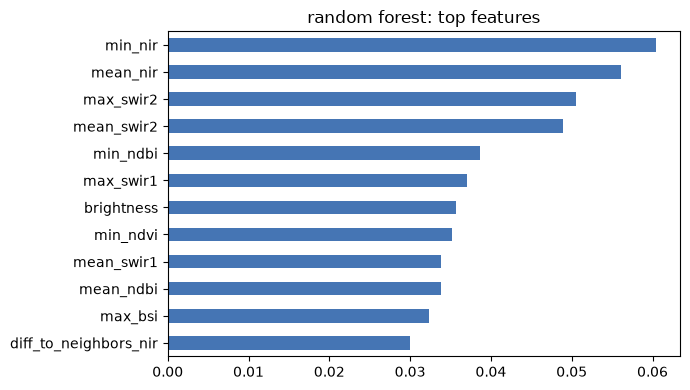

In [15]:
ref_pts = None
if REFERENCE_POINTS_PATH and Path(REFERENCE_POINTS_PATH).exists():
    import geopandas as gpd
    ref_pts = gpd.read_file(REFERENCE_POINTS_PATH)
elif not LIVE:
    ref_pts = scene.reference                      # the synthetic scene's exactly-correct points

ref_objs = pd.Index([])
if ref_pts is not None:
    ref_objs = obia.samples_from_geometries(lab, ref_pts, "class", rd.transform, crs=rd.crs).index
train = samples.drop(index=ref_objs, errors="ignore")
print(f"weak-label samples: {len(samples)}; held out for the independent check: {len(samples) - len(train)}; used for training: {len(train)}")

clf = obia.ObjectClassifier("rf", random_state=SEED, **clf_kw).fit(F, train)
rf = clf.predict(F)
print("random-forest objects per class:", rf.classes.value_counts().to_dict())
print(f"objects with NaN texture (too small for a co-occurrence matrix): {int(F['glcm_contrast_nir'].isna().sum())} -> filled with the median")
imp = clf.feature_importances_.head(12)
fig, ax = plt.subplots(figsize=(7, 4)); imp[::-1].plot.barh(ax=ax, color="#4575b4"); ax.set_title("random forest: top features"); plt.tight_layout(); plt.show()

## 9. Independent assessment

Only a reference that **did not come from WorldCover or OSM** and was **not used for training** can measure accuracy. Here that is a points file (`REFERENCE_POINTS_PATH`, or the synthetic scene's exactly-correct points). An object is assessed when a reference point falls in it.

In [16]:
results = {"rules": rules, "random forest": rf}
summary = []
if ref_pts is None:
    print("No independent reference provided -> NO accuracy is reported. Set REFERENCE_POINTS_PATH to a points file with a 'class' column.")
else:
    assert not set(ref_objs) & set(train.index), "a reference object leaked into training"
    print(f"{len(ref_pts)} reference points reach {len(ref_objs)} objects; none of them was a training sample")
    for name, res in results.items():
        a = obia.assess_classification(res, lab, ref_pts, "class", rd.transform, crs=rd.crs)
        summary.append({"classifier": name, "objects assessed": a["n_objects"],
                        "overall accuracy": a["overall_accuracy"], "kappa": a["kappa"]})
        print(f"\n{name}: OA {a['overall_accuracy']:.3f}, kappa {a['kappa']:.3f} on {a['n_objects']} reference objects")
        display(a["per_class"].round(3))
    print("\nA caution on the rules: their thresholds were read off the weak-label profile of this very scene, so they are")
    print("fitted to it as surely as the forest is. They are a baseline, not a second independent method.")

200 reference points reach 76 objects; none of them was a training sample

rules: OA 0.842, kappa 0.793 on 76 reference objects


,producers_accuracy,users_accuracy,f1,reference_total,predicted_total
built_up,0.895,1.000,0.944,19.0,17.0
farmland,0.533,0.727,0.615,15.0,11.0
forest,0.880,0.759,0.815,25.0,29.0
mine_disturbed,1.000,0.800,0.889,8.0,10.0
water,1.000,1.000,1.000,9.0,9.0



random forest: OA 0.829, kappa 0.781 on 76 reference objects


,producers_accuracy,users_accuracy,f1,reference_total,predicted_total
built_up,0.842,1.000,0.914,19.0,16.0
farmland,1.000,0.577,0.732,15.0,26.0
forest,0.680,1.000,0.810,25.0,17.0
mine_disturbed,0.750,0.750,0.750,8.0,8.0
water,1.000,1.000,1.000,9.0,9.0



A caution on the rules: their thresholds were read off the weak-label profile of this very scene, so they are
fitted to it as surely as the forest is. They are a baseline, not a second independent method.


In [17]:
if not LIVE:
    # DEMO ONLY: score every pixel against the complete truth (cloud pixels excluded). Real data cannot do this.
    unseen = valid & ~np.isin(lab, train.index)               # pixels of objects the forest never trained on
    truth_px = np.where(unseen, scene.truth, 0)
    print(f"how far apart are the three scores for the random forest? (pixel test set: {unseen.sum():,} px of objects not used for training)")
    px = obia.pixel_report(paint(rf.classes, lab), truth_px, CLASSES)
    ind = [s_ for s_ in summary if s_["classifier"] == "random forest"][0]["overall accuracy"]
    cmp = pd.DataFrame({
        "what it measures": ["held-out agreement with WEAK labels (spatial blocks)", "independent reference points (objects)", "complete truth, pixels of untrained objects"],
        "overall accuracy": [held["overall_accuracy"], ind, px["overall_accuracy"]]})
    display(cmp.round(3))
    print("Per-class accuracy against the complete truth (pixels of untrained objects):")
    display(px["per_class"].round(3))

how far apart are the three scores for the random forest? (pixel test set: 42,890 px of objects not used for training)


,what it measures,overall accuracy
0,held-out agreement with WEAK labels (spatial b...,0.757
1,independent reference points (objects),0.829
2,"complete truth, pixels of untrained objects",0.877


Per-class accuracy against the complete truth (pixels of untrained objects):


,producers_accuracy,users_accuracy,f1,reference_total,predicted_total
forest,0.609,0.999,0.756,11498.0,7005.0
farmland,0.999,0.822,0.902,23478.0,28510.0
built_up,0.749,0.994,0.854,1587.0,1196.0
mine_disturbed,0.936,0.973,0.954,5177.0,4983.0
water,1.000,0.962,0.980,1150.0,1196.0


## 10. Maps and areas

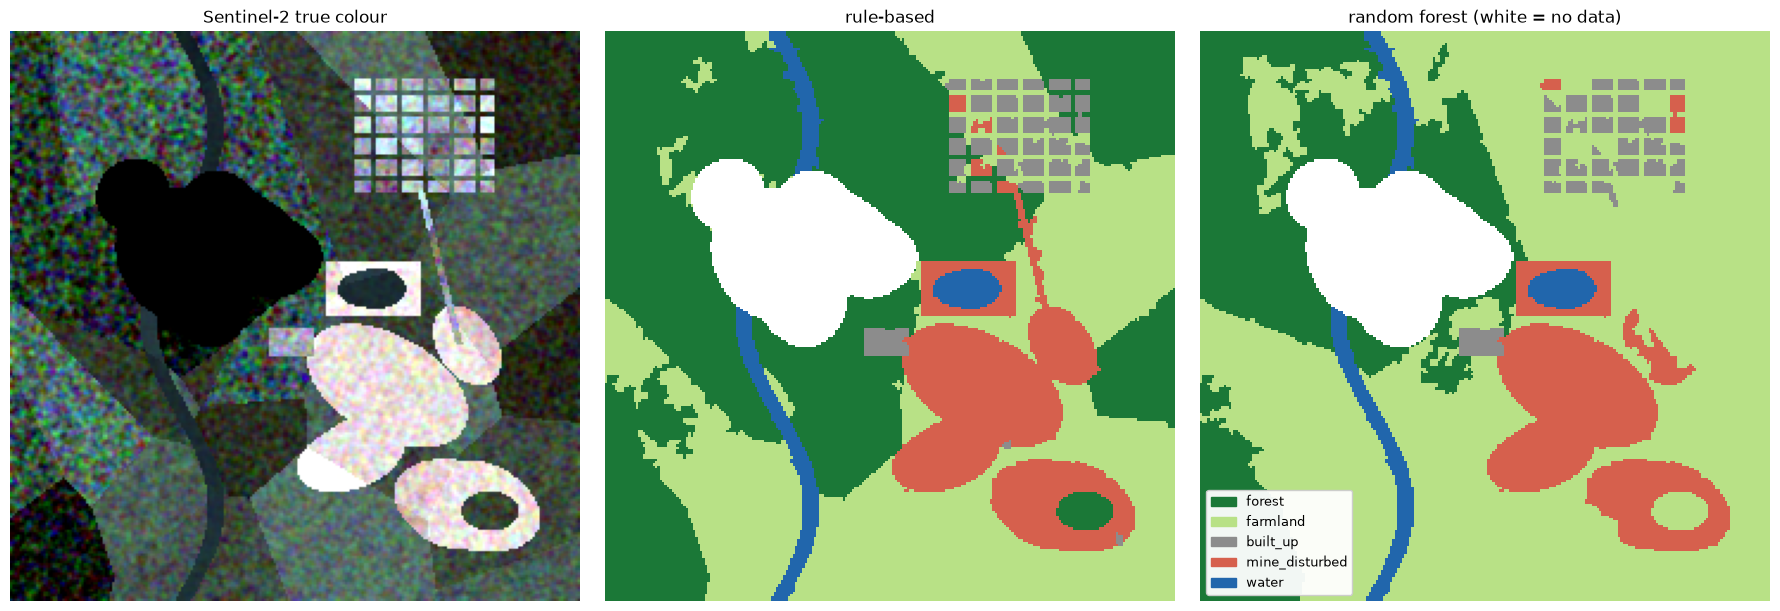

In [18]:
rf_ras = paint(rf.classes, lab)
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(rgb); ax[0].set_title("Sentinel-2 true colour"); ax[0].axis("off")
ax[1].imshow(paint(rules.classes, lab), cmap=CMAP, vmin=0, vmax=len(CLASSES), interpolation="nearest"); ax[1].set_title("rule-based"); ax[1].axis("off")
ax[2].imshow(rf_ras, cmap=CMAP, vmin=0, vmax=len(CLASSES), interpolation="nearest"); ax[2].set_title("random forest (white = no data)"); ax[2].axis("off")
ax[2].legend(handles=LEGEND, loc="lower left", fontsize=9, framealpha=.95)
plt.tight_layout(); plt.show()

In [19]:
# Area per class = sum of object areas (m2 -> ha). No-data pixels belong to no object, so they are reported separately.
areas = F["area_m2"].groupby(rf.classes).sum().reindex(CLASSES).fillna(0) / 1e4
tbl = pd.DataFrame({"objects": rf.classes.value_counts().reindex(CLASSES).fillna(0).astype(int), "area_ha": areas.round(1)})
tbl["share_of_mapped_%"] = (100 * tbl["area_ha"] / tbl["area_ha"].sum()).round(1)
tbl.loc["(no data: cloud/shadow)"] = [0, round((~valid).sum() * PIX_HA, 1), np.nan]
display(tbl)
tbl.to_csv(OUT / "area_by_class.csv")
if not LIVE:
    true_ha = pd.Series({c: ((scene.truth == CODE[c]) & valid).sum() * PIX_HA for c in CLASSES})
    print("DEMO ONLY - true area in the same valid pixels (ha):"); display(true_ha.round(1).to_frame("true_ha").join(areas.round(1).rename("mapped_ha")))

,objects,area_ha,share_of_mapped_%
class,,,
forest,103.0,109.7,20.8
farmland,78.0,327.7,62.0
built_up,30.0,15.5,2.9
mine_disturbed,20.0,58.7,11.1
water,20.0,16.8,3.2
(no data: cloud/shadow),0.0,47.6,NaN


DEMO ONLY - true area in the same valid pixels (ha):


,true_ha,mapped_ha
forest,163.6,109.7
farmland,264.4,327.7
built_up,22.8,15.5
mine_disturbed,61.4,58.7
water,16.2,16.8


**Reading the area table with care.** Classification errors do not cancel in a total: a class that is consistently under-called (here, compare `mapped_ha` with `true_ha` for forest) is under-counted in hectares even when overall accuracy looks fine. Small classes suffer most. For a number you will publish, do not add up mapped hectares; estimate area from a stratified independent reference sample with error adjustment (Olofsson et al., 2014, *Remote Sensing of Environment* 148). This notebook's table is a map summary, not an area estimate.

## 11. Export, and hand the mine footprint to `mine_rehabilitation`

Written to `obuasi_obia_outputs/`:

| File | What |
|---|---|
| `scene.tif` | the image used (NaN = no data) |
| `labels.tif` | object ids (0 = no data) |
| `classes.tif` | uint8 class raster: 1 forest, 2 farmland, 3 built_up, 4 mine_disturbed, 5 water, 0 = no data |
| `objects.gpkg` | every object with its class, class probabilities and features |
| `mine_site.geojson` | mine-disturbed objects dissolved into polygons (WGS84), parts under `MIN_MINE_HA` dropped |
| `area_by_class.csv` | the table above |

In [20]:
obia.save_raster(str(OUT / "scene.tif"), rd.image, rd.transform, rd.crs, rd.band_names)
seg.save(str(OUT / "labels.tif"))
obia.save_raster(str(OUT / "classes.tif"), rf_ras, rd.transform, rd.crs, dtype="uint8")
rf.to_vector(lab, rd.transform, rd.crs, features=F[["area_m2", "mean_ndvi", "mean_bsi", "mean_mndwi", "compactness"]]).to_file(OUT / "objects.gpkg", driver="GPKG")

import geopandas as gpd
from shapely.ops import unary_union
objs = rf.to_vector(lab, rd.transform, rd.crs)
mine_objs = objs[objs["class"] == "mine_disturbed"]
merged = unary_union(list(mine_objs.geometry))
parts = list(merged.geoms) if hasattr(merged, "geoms") else [merged]
site = gpd.GeoDataFrame({"part_id": range(1, len(parts) + 1)}, geometry=parts, crs=rd.crs)
site["area_ha"] = site.area / 1e4
site = site[site["area_ha"] >= MIN_MINE_HA].reset_index(drop=True)
site.to_crs(4326).to_file(OUT / "mine_site.geojson", driver="GeoJSON")
print(f"mine_site.geojson: {len(site)} part(s), {site['area_ha'].sum():.1f} ha (smallest {site['area_ha'].min():.1f} ha, largest {site['area_ha'].max():.1f} ha)")

# Does the pipeline accept this file as its `site` input?
from pygeovision.ai.pipelines.timeseries import _read_polygons
chk = _read_polygons(str(OUT / "mine_site.geojson"), "site")
print(f"mine_rehabilitation reads it: {len(chk)} polygon(s), CRS {chk.crs.to_string()}")
print(sorted(p.name for p in OUT.iterdir() if p.is_file()))

mine_site.geojson: 5 part(s), 58.3 ha (smallest 0.9 ha, largest 33.8 ha)
mine_rehabilitation reads it: 5 polygon(s), CRS EPSG:4326
['area_by_class.csv', 'classes.tif', 'labels.tif', 'mine_site.geojson', 'objects.gpkg', 'scene.tif']


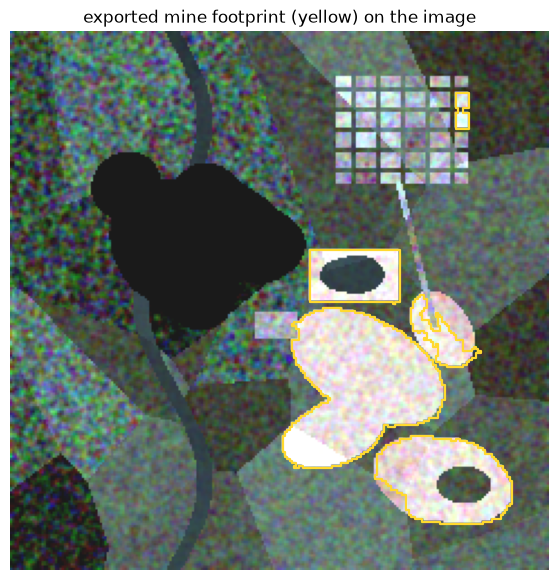

In [21]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(rgb, alpha=.9)
inv = ~rd.transform
for geom in site.geometry:
    for poly in (geom.geoms if hasattr(geom, "geoms") else [geom]):
        xs, ys = zip(*[inv * (x, y) for x, y in poly.exterior.coords])
        ax.plot(xs, ys, color="#ffd92f", lw=1.6)
ax.set_title("exported mine footprint (yellow) on the image"); ax.axis("off"); plt.show()

## 12. The same chain from the command line

`pygeovision obia ...` runs the same code from a shell. As a consistency check, segment the saved `scene.tif` with the CLI and compare with the label raster the Python API just produced: they should be **identical**.

In [22]:
import rasterio
def cli(*args):
    import shutil
    exe = [shutil.which("pygeovision")] if shutil.which("pygeovision") else [sys.executable, "-W", "ignore::RuntimeWarning", "-m", "pygeovision.cli.main"]
    r = subprocess.run([*exe, *map(str, args)], capture_output=True, text=True)
    return r.returncode, (r.stdout + r.stderr).strip()

rc, out = cli("obia", "segment", OUT / "scene.tif", "--scale", SCALE, "--output-labels", OUT / "labels_cli.tif")
print(out.splitlines()[-1] if out else "(no output)")
with rasterio.open(OUT / "labels_cli.tif") as a, rasterio.open(OUT / "labels.tif") as b:
    same = np.array_equal(a.read(1), b.read(1))
print("CLI labels identical to the Python API's:", same)
assert rc == 0 and same

rc, out = cli("obia", "scale", OUT / "scene.tif", "--scales", "8,12,16,20,30")
print(out)

✓ 251 objects (multires) → obuasi_obia_outputs/labels_cli.tif
CLI labels identical to the Python API's: True


n_objects     lv  roc_lv  candidate
scale                                     
8.0         1304  13.22     NaN      False
12.0         461  15.91   20.38      False
16.0         251  16.96    6.57      False
20.0         181  16.58   -2.24      False
30.0         110  16.97    2.32      False

  ROC-LV candidate scales (heuristic — verify visually): none


## 13. Next step: is the mine growing back?

`mine_site.geojson` is the `site` of the rehabilitation pipeline, which tracks how vegetation on a disturbed area recovers relative to an undisturbed reference, date by date:

```bash
pygeovision channel mine_rehabilitation \
    --bbox -1.700 6.180 -1.655 6.225 \
    --dates 2020-02,2021-02,2022-02,2023-02,2024-02 \
    --param site=obuasi_obia_outputs/mine_site.geojson \
    --output ./obuasi_rehabilitation
```

Before running it on a real site, open `mine_site.geojson` in QGIS over high-resolution imagery. Active pits and the processing plant are **not** rehabilitation targets, and an OBIA map will include them as "disturbed" wherever it cannot tell them apart from a revegetating spoil heap. Dropping them is a decision for a person who knows the site.

### What this notebook established, and what it did not

- OBIA handled cloud holes without inventing objects there, and the CLI reproduces the Python result exactly.
- The classifier trained on weak labels and was tested by spatial hold-out. In the synthetic demonstration the three scores -- weak-label agreement, independent points, and complete truth -- differ, which is why Section 9 refuses to quote an accuracy without an independent reference.
- **Not established for real Obuasi:** any accuracy figure. That needs your own reference points (`REFERENCE_POINTS_PATH`).
- Live imagery and WorldCover download were wired in through `obia.fetch_scene` / `obia.fetch_worldcover`; they run when the network and credentials are available.